In [1]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet"

file_path = data_dir / "yellow_tripdata_2026-05.parquet"

if not file_path.exists():
    urlretrieve(url, file_path)

file_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [2]:
import pandas as pd

df = pd.read_parquet(file_path)
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00


In [3]:
df.shape

(4090836, 20)

In [4]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

In [5]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
)

df["duration"] = df["duration"].dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

In [6]:
initial_count = len(df)

df = df[(df["duration"] >= 1) & (df["duration"] <= 60)].copy()

df.shape

(3883752, 21)

In [7]:
len(df) / initial_count * 100

94.93785622303118

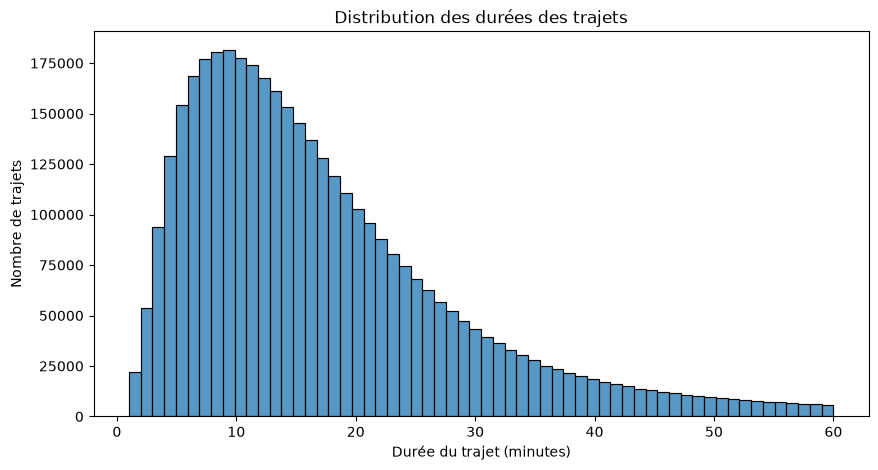

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df["duration"], bins=60)
plt.xlabel("Durée du trajet (minutes)")
plt.ylabel("Nombre de trajets")
plt.title("Distribution des durées des trajets")
plt.show()

In [9]:
categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)

df[categorical + numerical].head()

,PULocationID,DOLocationID,trip_distance
0,138,37,7.51
1,138,237,6.14
2,249,232,2.40
3,232,114,1.20
5,255,236,5.89


In [10]:
X = df[categorical + numerical]
y = df["duration"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (3883752, 3)
Dimensions de y : (3883752,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ImportError: libgomp.so.1: cannot open shared object file: No such file or directory

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ImportError: libgomp.so.1: cannot open shared object file: No such file or directory

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
print("X_train :", X_train.shape)
print("X_val :", X_val.shape)
print("y_train :", y_train.shape)
print("y_val :", y_val.shape)

X_train : (3107001, 3)
X_val : (776751, 3)
y_train : (3107001,)
y_val : (776751,)


In [17]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_encoded, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](519,)","[ 15.82,-18.98, -2.67,..., -1.41, 0.78, 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,25.14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,519


In [18]:
y_pred_lr = lr.predict(X_val_encoded)

y_pred_lr[:10]


array([11.61992683, 17.89250991, 15.39310877, 13.3731971 , 18.15605014,
       13.89833274, 14.66501991, 14.59717235, 32.91548684, 18.52717494])

In [19]:
from sklearn.metrics import root_mean_squared_error

rmse_lr = root_mean_squared_error(y_val, y_pred_lr)

print("RMSE Régression linéaire :", rmse_lr)

RMSE Régression linéaire : 9.621008415996018


In [21]:
import numpy as np
from sklearn.linear_model import Lasso

X_train_encoded = X_train_encoded.tocsc()
X_val_encoded = X_val_encoded.tocsc()

X_train_encoded.indices = X_train_encoded.indices.astype(np.int32)
X_train_encoded.indptr = X_train_encoded.indptr.astype(np.int32)

X_val_encoded.indices = X_val_encoded.indices.astype(np.int32)
X_val_encoded.indptr = X_val_encoded.indptr.astype(np.int32)

lasso = Lasso(alpha=0.01)
lasso.fit(X_train_encoded, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.01
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [22]:
y_pred_lasso = lasso.predict(X_val_encoded)

y_pred_lasso[:10]

array([11.68424846, 17.7685755 , 17.87682182, 14.15163616, 16.83455288,
       15.01728521, 14.97761934, 15.29158814, 32.66776953, 19.85131052])

In [23]:
rmse_lasso = root_mean_squared_error(y_val, y_pred_lasso)

print("RMSE Lasso :", rmse_lasso)

RMSE Lasso : 9.888807682414729


In [24]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

xgb_model.fit(X_train_encoded, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [25]:
y_pred_xgb = xgb_model.predict(X_val_encoded)

y_pred_xgb[:10]

array([ 6.8947353, 10.544066 ,  9.526358 , 11.524084 , 22.432745 ,
       16.494371 , 21.020308 ,  8.229327 , 43.540955 ,  5.0269384],
      dtype=float32)

In [26]:
rmse_xgb = root_mean_squared_error(y_val, y_pred_xgb)

print("RMSE XGBoost :", rmse_xgb)

RMSE XGBoost : 6.5492056576552


In [27]:
results = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Lasso", "XGBoost"],
    "RMSE": [rmse_lr, rmse_lasso, rmse_xgb]
})

results.sort_values("RMSE")

,Modèle,RMSE
2,XGBoost,6.549206
0,Régression linéaire,9.621008
1,Lasso,9.888808


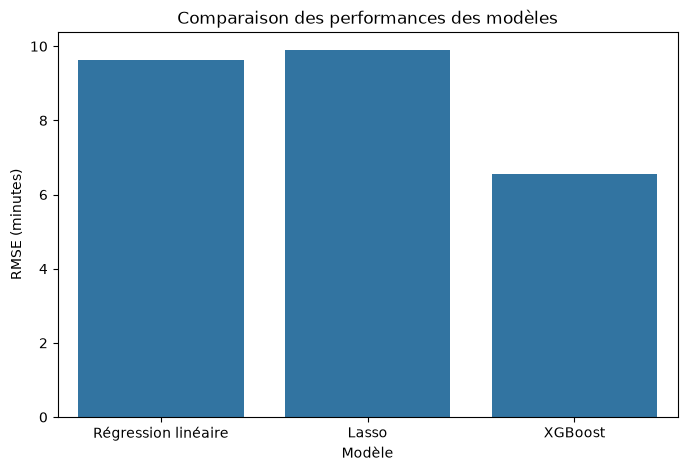

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(data=results, x="Modèle", y="RMSE")

plt.title("Comparaison des performances des modèles")
plt.ylabel("RMSE (minutes)")
plt.xlabel("Modèle")

plt.show()

In [29]:
best_model = results.loc[results["RMSE"].idxmin()]

print("Meilleur modèle :", best_model["Modèle"])
print("RMSE :", best_model["RMSE"], "minutes")

Meilleur modèle : XGBoost
RMSE : 6.5492056576552 minutes


In [30]:
print("Conclusion du TP")

print(f"Régression linéaire : {rmse_lr:.2f} minutes")
print(f"Lasso : {rmse_lasso:.2f} minutes")
print(f"XGBoost : {rmse_xgb:.2f} minutes")

print(f"Le modèle le plus performant est {best_model['Modèle']}")
print(f"Son RMSE est de {best_model['RMSE']:.2f} minutes.")

Conclusion du TP
Régression linéaire : 9.62 minutes
Lasso : 9.89 minutes
XGBoost : 6.55 minutes
Le modèle le plus performant est XGBoost
Son RMSE est de 6.55 minutes.
